# Synthetic Difference-in-Differences на `smoking.csv`

В этом демо пошагово показываем весь API из `synthetic_difference_in_differences.py`: базовый классовый интерфейс, функциональные обертки, low-level helper-функции, регуляризацию, residualization, по-периодные эффекты, staggered adoption и визуализации.


## 1. Импорты и окружение

Что делаем: импортируем все публичные SDID-инструменты, которые хотим покрыть в ноутбуке.

Зачем: чтобы видно было единый API и варианты использования под разные задачи.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if (ROOT / 'cib_advanced_experiments').exists():
    repo_root = ROOT
else:
    repo_root = ROOT.parent

if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

from cib_advanced_experiments import (
    SyntheticDifferenceInDifferences,
    synthetic_difference_in_differences,
    fit_sdid,
    fit_staggered_sdid,
    fit_unit_weights,
    fit_time_weights,
    join_sdid_weights,
    residualize_outcome,
    calculate_sigma_hat,
    calculate_regularization,
    calculate_time_regularization,
)


## 2. Загружаем и подготавливаем панель

Что делаем: читаем `smoking.csv`, приводим идентификаторы и время к удобному типу, формируем `treated` и `post`.

Зачем: SDID требует панель с явными бинарными индикаторами treatment-group и post-period.


In [2]:
data_path = Path('data/smoking.csv')
if not data_path.exists():
    data_path = Path('notebooks/data/smoking.csv')

df = pd.read_csv(data_path)
df['state'] = df['state'].astype(str)
df['date'] = pd.to_datetime(df['year'].astype(str) + '-01-01')

treated_state = df.loc[df['california'] == True, 'state'].iloc[0]
treatment_date = pd.Timestamp('1989-01-01')

did_data = df.copy()
did_data['treated'] = (did_data['state'] == treated_state).astype(int)
did_data['post'] = (did_data['date'] >= treatment_date).astype(int)

did_data[['state', 'date', 'cigsale', 'treated', 'post']].head()


,state,date,cigsale,treated,post
0,1,1970-01-01,89.800003,0,0
1,1,1971-01-01,95.400002,0,0
2,1,1972-01-01,101.099998,0,0
3,1,1973-01-01,102.900002,0,0
4,1,1974-01-01,108.199997,0,0


## 3. Базовая оценка через класс `SyntheticDifferenceInDifferences`

Что делаем: инициализируем модель и вызываем `fit` с классическим набором параметров.

Зачем: это основной high-level путь для блоковой постановки treated/control + pre/post.


In [3]:
sdid = SyntheticDifferenceInDifferences(
    data=did_data,
    outcome_column='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
)
result = sdid.fit(
    alpha=0.05,
    optimizer_tolerance=1e-5,
)

print('SDID ATT:', round(result.estimate, 4))
print('p-value:', round(result.pvalue, 4))
print('CI:', (round(result.ci_lower, 4), round(result.ci_upper, 4)))
print('n_obs:', result.n_obs)


SDID ATT: -15.6057
p-value: 0.0
CI: (-21.2161, -9.9952)
n_obs: 1209


## 4. Декомпозиция оценок и диагностика трендов

Что делаем: смотрим таблицу наивных оценок против SDID и формируем фрейм параллельных трендов.

Зачем: удобно проверить, как SDID корректирует простые before/after сравнения и что происходит с pre-trend.


In [4]:
breakdown = sdid.get_estimators_breakdown()
trends_pre = sdid.get_parallel_trends_frame(pre_period_only=True)

breakdown, trends_pre.head()


(                              estimator      value
 0            naive_before_after_treated -34.795870
 1  naive_post_period_treated_vs_control -40.865201
 2            sdid_controlled_difference -15.605664,
 treated_flag       time  control_mean  treated_mean        gap
 0            1970-01-01    141.818045    123.000000 -18.818045
 1            1971-01-01    145.121834    121.000000 -24.121834
 2            1972-01-01    149.743117    123.500000 -26.243117
 3            1973-01-01    149.037974    124.400002 -24.637973
 4            1974-01-01    150.122020    126.699997 -23.422023)

## 5. Веса SDID

Что делаем: проверяем юнит- и тайм-веса, а также их нормировку.

Зачем: интерпретация SDID строится на reweighting controls и pre-периодов.


In [5]:
print('Sum(unit_weights):', round(float(result.unit_weights.sum()), 6))
print('Sum(time_weights):', round(float(result.time_weights.sum()), 6))

result.unit_weights.head(10), result.time_weights.head(10)


Sum(unit_weights): 1.0
Sum(time_weights): 1.0


(state
 21    0.124196
 22    0.104566
 5     0.078361
 6     0.070432
 4     0.057419
 9     0.053462
 20    0.048048
 19    0.045190
 34    0.041668
 23    0.040725
 Name: unit_weight, dtype: float64,
 date
 1970-01-01    6.691716e-11
 1971-01-01    4.493195e-11
 1972-01-01    3.029922e-11
 1973-01-01    4.304689e-11
 1974-01-01    3.783415e-11
 1975-01-01    8.076160e-12
 1976-01-01    0.000000e+00
 1977-01-01    0.000000e+00
 1978-01-01    0.000000e+00
 1979-01-01    0.000000e+00
 Name: time_weight, dtype: float64)

## 6. Продвинутый `fit`: residualization + clustered SE

Что делаем: перед SDID вычитаем эффект ковариат и считаем кластер-робастные ошибки.

Зачем: это полезно, если есть наблюдаемые факторы и риск занижения SE из-за внутрикластерной корреляции.


In [6]:
advanced_result = sdid.fit(
    alpha=0.05,
    covariate_columns=['retprice', 'age15to24'],
    cluster_by_unit=True,
    cluster_column='state',
    optimizer_tolerance=1e-5,
)

print('Model outcome:', advanced_result.model_outcome_column)
print('Residualized:', advanced_result.residualized)
print('Clustered SE:', advanced_result.used_clustered_se)
print('Cluster column:', advanced_result.cluster_column)


Model outcome: cigsale_resid
Residualized: True
Clustered SE: True
Cluster column: state


## 7. Альтернативная спецификация инференса

Что делаем: отключаем fixed effects и кластеризацию, чтобы сравнить режимы оценки.

Зачем: API позволяет явно контролировать trade-off между простотой спецификации и устойчивостью инференса.


In [7]:
plain_result = sdid.fit(
    use_fixed_effects=False,
    cluster_by_unit=False,
    optimizer_tolerance=1e-5,
)

print('Estimate (no FE/no cluster):', round(plain_result.estimate, 4))
print('used_fixed_effects:', plain_result.used_fixed_effects)
print('used_clustered_se:', plain_result.used_clustered_se)


Estimate (no FE/no cluster): -15.6057
used_fixed_effects: False
used_clustered_se: False


## 8. По-периодные эффекты после интервенции

Что делаем: считаем отдельный SDID-эффект для каждого пост-периода.

Зачем: это упрощенный event-study взгляд на динамику эффекта.


In [8]:
period_effects = sdid.fit_effects_by_period(
    alpha=0.05,
    optimizer_tolerance=1e-4,
)
period_effects.head()


,period,estimate,std_error,pvalue,ci_lower,ci_upper,n_obs
0,1989-01-01,-4.169264,0.736741,0.000002,-5.660717,-2.677811,780
1,1990-01-01,-3.723620,2.465119,0.139182,-8.713992,1.266753,780
2,1991-01-01,-7.013988,3.354639,0.043284,-13.805101,-0.222876,780
3,1992-01-01,-6.563370,3.850140,0.096413,-14.357572,1.230832,780
4,1993-01-01,-11.177924,3.877623,0.006455,-19.027761,-3.328086,780


## 9. One-shot функциональный API

Что делаем: вызываем `synthetic_difference_in_differences(...)` без явного создания объекта.

Зачем: удобно для лаконичных пайплайнов и скриптов, когда объект модели не нужен.


In [9]:
one_shot = synthetic_difference_in_differences(
    data=did_data,
    outcome_column='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    optimizer_tolerance=1e-5,
)

print('One-shot ATT:', round(one_shot.estimate, 4))


One-shot ATT: -15.6057


## 10. Wrapper `fit_sdid` (совместимость payload-формата)

Что делаем: используем совместимую обертку `fit_sdid`.

Зачем: удобно для миграции со старых скриптов, где ожидается словарь с `att`, весами и метаданными.


In [10]:
payload = fit_sdid(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    covariate_cols=['retprice', 'age15to24'],
    optimizer_tolerance=1e-5,
)

{k: payload[k] for k in ['att', 'pvalue', 'model_outcome_col', 'used_clustered_se']}


{'att': -8.812813674791856,
 'pvalue': 0.0009412115458171666,
 'model_outcome_col': 'cigsale_resid',
 'used_clustered_se': True}

## 11. Low-level helpers для весов

Что делаем: отдельно фитим `unit_weights` и `time_weights`, затем объединяем их в панель через `join_sdid_weights`.

Зачем: это полезно для отладки и кастомных сценариев, где нужно управлять весами вручную.


In [11]:
unit_w = fit_unit_weights(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    optimizer_tolerance=1e-5,
)
time_w = fit_time_weights(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    zeta_time_small=1e-8,
    optimizer_tolerance=1e-5,
)
joined_w = join_sdid_weights(
    panel=did_data,
    unit_weights=unit_w,
    time_weights=time_w,
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    outcome_column='cigsale',
)

unit_w.head(), time_w.head(), joined_w[['unit_weight', 'time_weight', 'sdid_weight']].head()


(state
 21    0.124196
 22    0.104566
 5     0.078361
 6     0.070432
 4     0.057419
 Name: unit_weight, dtype: float64,
 date
 1970-01-01    6.691716e-11
 1971-01-01    4.493195e-11
 1972-01-01    3.029922e-11
 1973-01-01    4.304689e-11
 1974-01-01    3.783415e-11
 Name: time_weight, dtype: float64,
     unit_weight   time_weight   sdid_weight
 0  1.815123e-12  6.691716e-11  1.000000e-12
 1  1.031259e-02  6.691716e-11  1.000000e-12
 2  2.618297e-02  6.691716e-11  1.752090e-12
 3  2.181524e-02  6.691716e-11  1.459814e-12
 4  9.179485e-12  6.691716e-11  1.000000e-12)

## 12. Вспомогательные функции: residuals и регуляризация

Что делаем: отдельно вызываем `residualize_outcome`, `calculate_sigma_hat`, `calculate_regularization`, `calculate_time_regularization`.

Зачем: можно понять промежуточные величины, которые напрямую влияют на SDID-веса.


In [12]:
resid_df, resid_col, resid_model = residualize_outcome(
    panel=did_data,
    outcome_col='cigsale',
    covariate_cols=['retprice', 'age15to24'],
    treatment_column='treated',
    post_column='post',
)
sigma_hat = calculate_sigma_hat(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
)
zeta = calculate_regularization(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
)
zeta_time = calculate_time_regularization(
    panel=did_data,
    outcome_col='cigsale',
    unit_column='state',
    time_column='date',
    treatment_column='treated',
    post_column='post',
    ridge_scale=1e-6,
)

print('Residual column:', resid_col)
print('n residual-model features:', len(resid_model['feature_columns']))
print('sigma_hat:', sigma_hat)
print('zeta:', zeta)
print('zeta_time:', zeta_time)


Residual column: cigsale_resid
n residual-model features: 3
sigma_hat: 5.494401019461255
zeta: 10.226232573132346
zeta_time: 5.494401019461254e-06


## 13. `fit_staggered_sdid` на синтетическом staggered-adoption примере

Что делаем: собираем небольшую панель с двумя когортами старта лечения и считаем cohort-level + aggregate ATT.

Зачем: показать поддержку неодновременного внедрения treatment, а не только классического block-treatment случая.


In [13]:
rng = np.random.default_rng(42)
dates = pd.date_range('2024-01-01', periods=12, freq='D')
never_treated = [f'c{i}' for i in range(8)]
cohort_a = ['t0', 't1']
cohort_b = ['t2', 't3']
starts = {
    't0': pd.Timestamp('2024-01-06'),
    't1': pd.Timestamp('2024-01-06'),
    't2': pd.Timestamp('2024-01-09'),
    't3': pd.Timestamp('2024-01-09'),
}

rows = []
for unit in never_treated + cohort_a + cohort_b:
    treated = int(unit.startswith('t'))
    unit_fe = rng.normal(0.0, 0.3)
    start = starts.get(unit)
    for idx, d in enumerate(dates):
        post = int(treated and d >= start)
        y = (
            15.0
            + unit_fe
            + 0.1 * idx
            + 0.25 * treated
            + 0.2 * post
            + 2.0 * post
            + rng.normal(0.0, 0.08)
        )
        rows.append({'unit': unit, 'date': d, 'treated': treated, 'post': post, 'y': y})

staggered_df = pd.DataFrame(rows)

staggered_res = fit_staggered_sdid(
    data=staggered_df,
    outcome_col='y',
    unit_column='unit',
    time_column='date',
    treatment_column='treated',
    post_column='post',
)

print('Aggregate staggered ATT:', round(staggered_res.aggregate_estimate, 4))
staggered_res.cohort_results


Aggregate staggered ATT: 2.1674


,cohort_date,estimate,std_error,pvalue,ci_lower,ci_upper,n_obs,n_treated_units,n_control_units,n_treated_post_obs
0,2024-01-06,2.173196,0.033881,1.554312e-15,2.098623,2.247769,136,2,10,14
1,2024-01-09,2.157212,0.038946,1.025180e-12,2.069110,2.245313,120,2,8,8


## 14. Визуальные диагностики

Что делаем: строим 2x2 диаграмму и график параллельных трендов.

Зачем: быстрый sanity-check, что оценка и предпосылки модели выглядят адекватно на данных.


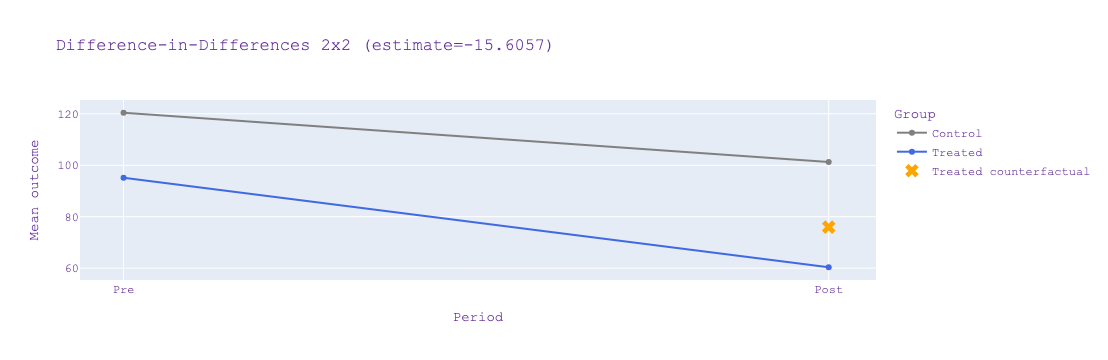

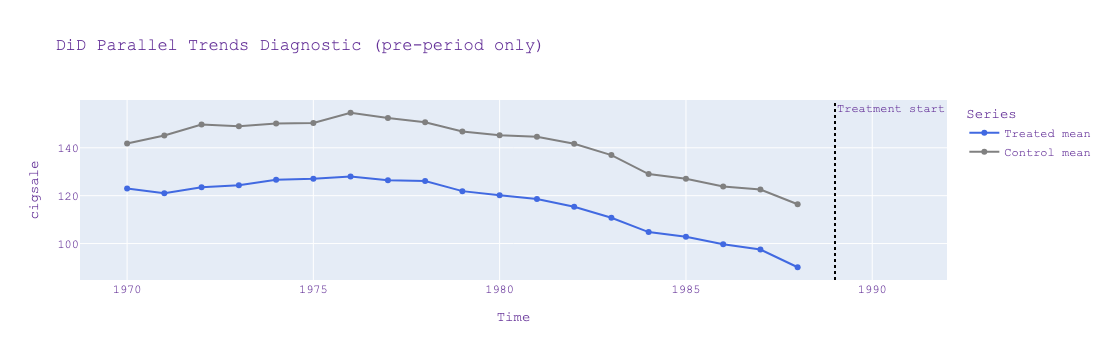

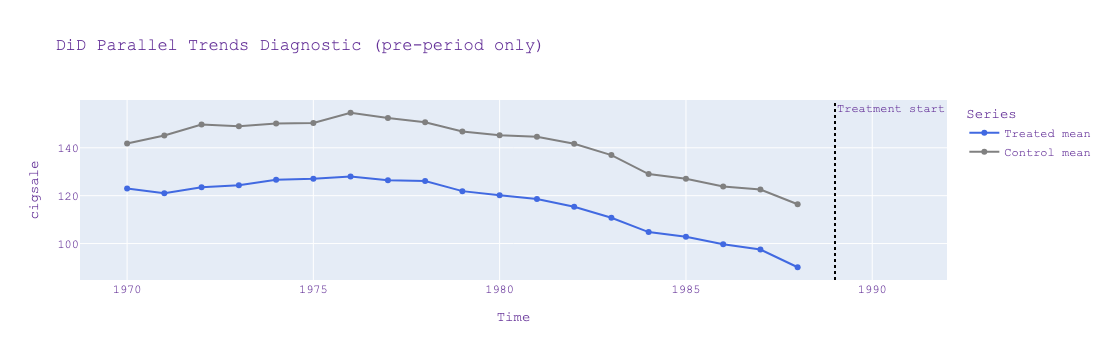

In [14]:
sdid.plot_2x2()
sdid.plot_parallel_trends(treatment_start=treatment_date, pre_period_only=True)


## 15. Что покрыто в этом демо

Покрыты: `SyntheticDifferenceInDifferences`, `synthetic_difference_in_differences`, `fit_sdid`, `fit_staggered_sdid`, `fit_unit_weights`, `fit_time_weights`, `join_sdid_weights`, `residualize_outcome`, `calculate_sigma_hat`, `calculate_regularization`, `calculate_time_regularization`, `fit_effects_by_period`, `get_estimators_breakdown`, `get_parallel_trends_frame`, `plot_2x2`, `plot_parallel_trends`.
